# Resultados con el formato de Salazar-Peña et al. (2025)

La profesora pidió presentar los resultados lo más parecido posible a Salazar-Peña et al.
(2025), que pronostica la irradiancia solar de la planta El Paso con una LSTM, una
Bi-LSTM y un Transformer. Este notebook toma los pronósticos del test que ya guardó cada
modelo y los presenta con las métricas y las gráficas de ese paper. No entrena nada ni
repite el test.

| En el paper | Aquí |
|---|---|
| MAE, RMSE, nRMSE, MBE y MAPE por horizonte (figuras 15 a 23) | Lo mismo, en COP/kWh y en %, para h = 3 a 9 |
| Intervalo t al 95% del error en cada horizonte | Lo mismo, sobre el error promedio de cada día |
| Skill score contra un modelo de referencia (figura 24) | Contra el ingenuo del día |
| MAPE por hora del día, una curva por horizonte (figuras 17, 20 y 23) | Lo mismo |
| Mapa de calor del mejor modelo por horizonte y hora (figuras 10 a 12) | Lo mismo |
| Días de ejemplo y su correlación con el real (figuras 28 a 37) | Semanas de ejemplo elegidas con una regla fija, y la semana final |
| Tablas de hiperparámetros (tablas 7 a 9) | Las de cada modelo |

Modelos: XGBoost y SARIMAX. Las dos LSTM entran solas cuando existan sus pronósticos en
`resultados/modelo_lstm/` y `resultados/modelo_lstm_v2/` (`prueba_2023_2025.csv.gz` y
`prueba_2026.csv.gz`, con `fecha`, `hora`, `h` e `y_hat`, como XGBoost). Periodos: 2023-2025 y 2026 hasta el 6 de
octubre. h es el número de días desde el último precio conocido: h = 3 es mañana.

Fuente del formato: Salazar-Peña, N. et al. (2025). Intra-day Solar and Power Forecast for
Optimization of Intraday Market Participation. arXiv:2501.09551v3.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from scipy import stats

# pandas 2.3 con numpy 2.5 avisa por una unidad que usa por dentro; no afecta el resultado
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

SALIDA = Path("resultados/comparacion")
SALIDA.mkdir(parents=True, exist_ok=True)
HS = list(range(3, 10))
PERIODOS = ["2023-2025", "2026"]
REFERENCIA = "ingenuo del día"

# Paleta categórica de la guía de gráficas del proyecto, en orden fijo: el color sigue
# al modelo en todas las figuras. Los ingenuos van en gris porque son referencias.
COLOR = {"precio real": "#2a78d6", "XGBoost": "#eb6834", "SARIMAX": "#1baf7a", "LSTM": "#eda100",
         "LSTM v2": "#e87ba4", "ingenuo del día": "#898781", "ingenuo semanal": "#c3c2b7"}
# Rampa azul para lo que tiene orden (los horizontes), del paso 250 al 700
AZULES = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#256abf", "#184f95", "#0d366b"]
FONDO, TEXTO, TEXTO_2, REJILLA = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({"figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
                     "axes.edgecolor": REJILLA, "axes.labelcolor": TEXTO_2, "text.color": TEXTO,
                     "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "axes.grid": True,
                     "grid.color": REJILLA, "grid.linewidth": 1, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10})


def guardar_figura(fig, nombre):
    fig.savefig(SALIDA / nombre, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Los pronósticos

El precio pronosticado es P(t, H)·exp(ŷ), como en cada modelo. El ingenuo del día repite el
precio de la misma hora del último día conocido; el semanal, el del mismo día de la semana
más reciente que se conozca.

In [2]:
def xgboost():
    a = pd.concat([pd.read_csv(f"resultados/modelo_xgboost/prueba_h{h}.csv.gz") for h in HS])
    b = pd.read_csv("resultados/modelo_xgboost/prueba2026_mensual.csv.gz").query("h in @HS")
    d = pd.concat([a.assign(periodo="2023-2025"), b.assign(periodo="2026")], ignore_index=True)
    d["precio real"] = d["precio_t"] * np.exp(d["y"])
    d["XGBoost"] = d["precio_t"] * np.exp(d["y_hat"])
    d["ingenuo del día"] = d["precio_t"]
    d["ingenuo semanal"] = d["precio_t"] * np.exp(d["y_semanal"])
    return d.drop(columns=["y", "y_hat", "y_semanal"])


def sarimax():
    s = pd.concat([pd.read_csv("resultados/modelo_sarimax/prueba_2023_2025.csv.gz"),
                   pd.read_csv("resultados/modelo_sarimax/prueba_2026.csv.gz")], ignore_index=True)
    return s.assign(SARIMAX=np.exp(s["lp_hat"]))[["fecha", "hora", "h", "SARIMAX"]]


LSTMS = {"LSTM": Path("resultados/modelo_lstm"), "LSTM v2": Path("resultados/modelo_lstm_v2")}


def lstm(carpeta):
    rutas = [carpeta / f for f in ("prueba_2023_2025.csv.gz", "prueba_2026.csv.gz")]
    if not all(r.exists() for r in rutas):
        return None
    l = pd.concat([pd.read_csv(r) for r in rutas], ignore_index=True)
    return l[["fecha", "hora", "h", "y_hat"]].rename(columns={"y_hat": "y_hat_lstm"})


x = xgboost()
ancho = x.merge(sarimax(), on=["fecha", "hora", "h"], how="inner", validate="one_to_one")
assert len(ancho) == len(x), "XGBoost y SARIMAX no tienen las mismas filas"
MODELOS = ["XGBoost", "SARIMAX"]
for nombre, carpeta in LSTMS.items():
    l = lstm(carpeta)
    if l is None:
        continue
    ancho = ancho.merge(l, on=["fecha", "hora", "h"], how="inner", validate="one_to_one")
    assert len(ancho) == len(x), f"{nombre} no tiene las mismas filas"
    ancho[nombre] = ancho["precio_t"] * np.exp(ancho.pop("y_hat_lstm"))
    MODELOS.append(nombre)
ancho["fecha"] = pd.to_datetime(ancho["fecha"])
REFS = ["ingenuo del día", "ingenuo semanal"]
TODOS = MODELOS + REFS

largo = ancho.melt(id_vars=["periodo", "fecha", "hora", "h", "precio real"], value_vars=TODOS,
                   var_name="modelo", value_name="pronostico")
largo["error"] = largo["pronostico"] - largo["precio real"]
print(f"{len(ancho):,} filas (día de corte, hora, h) por modelo; modelos: {', '.join(MODELOS)}")
print(ancho.groupby("periodo").agg(filas=("h", "size"), cortes=("fecha", "nunique"),
                                   desde=("fecha", "min"), hasta=("fecha", "max")))

228,984 filas (día de corte, hora, h) por modelo; modelos: XGBoost, SARIMAX
            filas  cortes      desde      hasta
periodo                                        
2023-2025  183120    1093 2023-01-01 2025-12-28
2026        45864     276 2026-01-01 2026-10-03


## 2. Métricas por horizonte

Las del paper, con el error definido como pronóstico menos real:

- MAE: error absoluto medio, en COP/kWh.
- RMSE: raíz del error cuadrático medio, en COP/kWh.
- nRMSE: RMSE sobre el precio real medio, en %.
- MBE: error medio, en COP/kWh. Positivo: el modelo pronostica por encima del real.
- MAPE: error absoluto sobre el real, en %.
- Skill score: 1 − RMSE del modelo / RMSE de la referencia, en %. La referencia es el
  ingenuo del día; en el paper era el Transformer.

El intervalo es el del paper, con la t de Student al 95%, pero sobre el error promedio de
cada día: las 24 horas de un día comparten el mismo estado del sistema y contarlas por
separado haría el intervalo demasiado angosto. Los días seguidos también se parecen, así que
estos intervalos son una guía; la comparación formal entre modelos es Diebold-Mariano, en el
RESULTADOS.md de cada modelo.

In [3]:
def metricas(g):
    e, real = g["error"], g["precio real"]
    rmse = np.sqrt(np.mean(e ** 2))
    return pd.Series({"MAE": e.abs().mean(), "RMSE": rmse, "nRMSE": 100 * rmse / real.mean(),
                      "MBE": e.mean(), "MAPE": 100 * (e.abs() / real).mean()})


def con_skill(t):
    ref = t.xs(REFERENCIA, level="modelo")["RMSE"]
    t["skill"] = 100 * (1 - t["RMSE"] / ref.reindex(t.index.droplevel("modelo")).to_numpy())
    return t


por_h = con_skill(largo.groupby(["periodo", "modelo", "h"])[["error", "precio real"]].apply(metricas))
semana = con_skill(largo.groupby(["periodo", "modelo"])[["error", "precio real"]].apply(metricas))
por_h.round(2).to_csv(SALIDA / "metricas_por_horizonte.csv")
semana.round(2).to_csv(SALIDA / "metricas_semana.csv")

print("Toda la semana (h = 3 a 9):")
display(semana.reindex(TODOS, level="modelo").round(2))

Toda la semana (h = 3 a 9):

MAE    RMSE  nRMSE    MBE   MAPE  skill
periodo   modelo                                                     
2023-2025 XGBoost          148.63  247.49  50.35 -46.43  36.17   3.72
          SARIMAX          148.76  242.14  49.27 -15.33  39.03   5.80
          ingenuo del día  150.10  257.05  52.30   1.30  40.12   0.00
          ingenuo semanal  172.10  286.26  58.24   1.76  46.82 -11.36
2026      XGBoost          122.48  175.67  35.99 -38.01  29.45   6.79
          SARIMAX          122.85  176.48  36.15 -29.17  30.42   6.36
          ingenuo del día  127.12  188.48  38.61  -8.28  32.43   0.00
          ingenuo semanal  143.93  204.39  41.87 -13.00  37.17  -8.44

In [4]:
# Intervalo t al 95% sobre el error promedio de cada día
dia = (largo.assign(ae=largo["error"].abs(), e2=largo["error"] ** 2)
            .groupby(["periodo", "modelo", "h", "fecha"])[["ae", "error", "e2"]].mean())


def intervalo(v):
    n = len(v)
    m, ee = v.mean(), v.std(ddof=1) / np.sqrt(n)
    t = stats.t.ppf(0.975, n - 1)
    return m, m - t * ee, m + t * ee


filas = []
for (p, mo, h), g in dia.groupby(level=["periodo", "modelo", "h"]):
    mae, mae_lo, mae_hi = intervalo(g["ae"])
    mbe, mbe_lo, mbe_hi = intervalo(g["error"])
    mse, mse_lo, mse_hi = intervalo(g["e2"])
    filas.append(dict(periodo=p, modelo=mo, h=h, dias=len(g), MAE=mae, MAE_lo=mae_lo, MAE_hi=mae_hi,
                      MBE=mbe, MBE_lo=mbe_lo, MBE_hi=mbe_hi, RMSE=np.sqrt(mse),
                      RMSE_lo=np.sqrt(max(mse_lo, 0)), RMSE_hi=np.sqrt(mse_hi)))
ic = pd.DataFrame(filas).set_index(["periodo", "modelo", "h"])
ic.round(2).to_csv(SALIDA / "intervalos_por_horizonte.csv")

for p in PERIODOS:
    print(f"\n{p}: MAE, RMSE, nRMSE, MBE (COP/kWh) y MAPE, skill score (%) por horizonte")
    t = por_h.loc[p].reindex(TODOS, level="modelo")
    display(t.unstack("h").round(1).loc[:, ["MAE", "RMSE", "MAPE", "skill"]])


2023-2025: MAE, RMSE, nRMSE, MBE (COP/kWh) y MAPE, skill score (%) por horizonte


MAE                                             RMSE  \
h                    3      4      5      6      7      8      9      3   
modelo                                                                    
XGBoost          101.8  119.9  128.8  151.8  168.9  181.3  188.2  180.0   
SARIMAX          115.0  129.1  140.6  149.6  158.2  170.2  179.0  193.6   
ingenuo del día  114.5  130.5  142.9  150.4  158.1  171.8  182.7  207.0   
ingenuo semanal  157.7  157.8  157.9  158.0  158.1  207.7  207.8  265.8   

                               ...  MAPE             skill                   \
h                    4      5  ...     7     8     9     3     4     5    6   
modelo                         ...                                            
XGBoost          206.8  221.4  ...  40.1  43.1  44.6  13.1   9.3  10.3  3.3   
SARIMAX          213.3  230.3  ...  41.9  45.6  48.3   6.5   6.4   6.6  5.5   
ingenuo del día  227.9  246.7  ...  42.3  46.9  50.5   0.0   0.0   0.0  0.0   
ingenuo semanal  265.9  266.0  ...  42.3  58.4  58.4 -28.4 -16.7  -7.9 -3.9   

                                  
h                  7     8     9  
modelo                            
XGBoost         -1.4  -0.5   0.4  
SARIMAX          4.4   5.6   6.0  
ingenuo del día  0.0   0.0   0.0  
ingenuo semanal  0.0 -16.0 -11.2  

[4 rows x 28 columns]


2026: MAE, RMSE, nRMSE, MBE (COP/kWh) y MAPE, skill score (%) por horizonte


MAE                                             RMSE  \
h                    3      4      5      6      7      8      9      3   
modelo                                                                    
XGBoost           88.7  104.3  113.0  123.4  133.4  143.2  152.2  139.7   
SARIMAX           97.6  108.9  117.5  123.7  130.4  138.1  144.5  147.8   
ingenuo del día  100.0  113.4  122.6  127.0  133.6  142.5  151.6  162.6   
ingenuo semanal  132.0  132.4  132.8  133.2  133.6  171.9  172.3  189.3   

                               ...  MAPE             skill                   \
h                    4      5  ...     7     8     9     3     4     5    6   
modelo                         ...                                            
XGBoost          155.1  163.5  ...  32.6  34.2  36.4  14.1  12.0  11.1  5.4   
SARIMAX          159.9  169.0  ...  32.5  34.4  35.9   9.1   9.3   8.1  5.1   
ingenuo del día  176.2  183.9  ...  34.3  36.8  39.2   0.0   0.0   0.0  0.0   
ingenuo semanal  189.7  190.0  ...  34.3  44.9  45.0 -16.4  -7.6  -3.3 -2.9   

                                  
h                  7     8     9  
modelo                            
XGBoost          3.3   3.4   3.2  
SARIMAX          3.9   4.7   6.0  
ingenuo del día  0.0   0.0   0.0  
ingenuo semanal  0.0 -16.8 -10.6  

[4 rows x 28 columns]

## 3. Error por horizonte

Como las figuras 15, 18 y 21 del paper: MAE, RMSE y MBE de cada modelo según el horizonte,
con su intervalo al 95%.

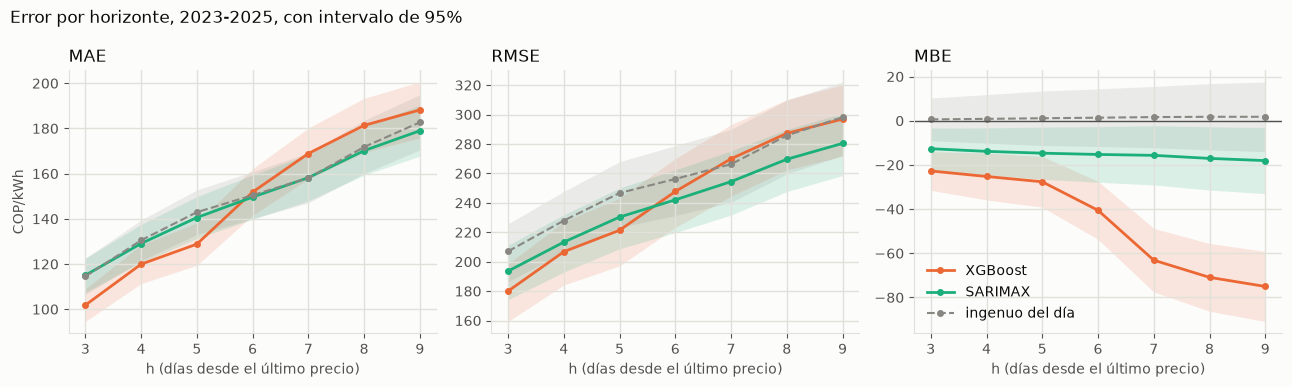

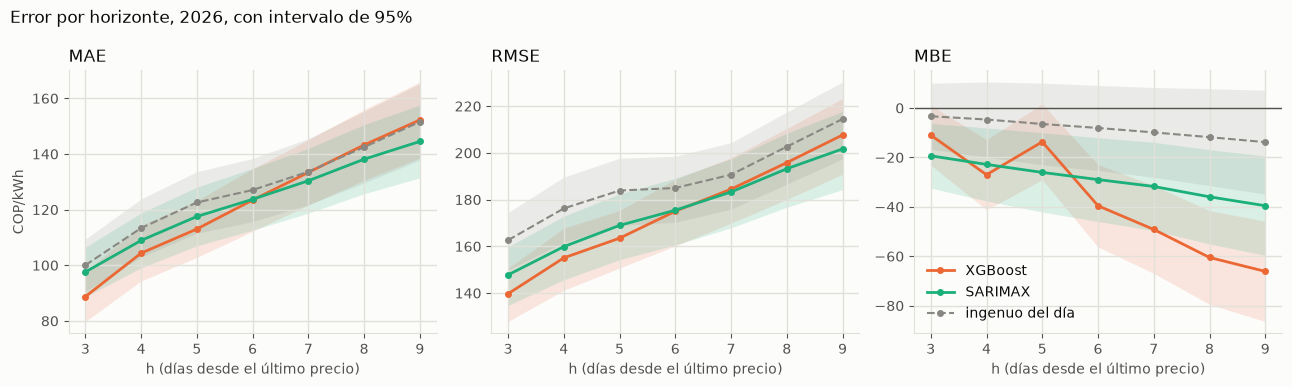

In [5]:
def error_por_horizonte(p, nombre):
    fig, ejes = plt.subplots(1, 3, figsize=(13, 3.9))
    for ax, m in zip(ejes, ["MAE", "RMSE", "MBE"]):
        for mo in MODELOS + [REFERENCIA]:
            d = ic.loc[(p, mo)]
            estilo = dict(ls="--", lw=1.5) if mo in REFS else {}
            ax.plot(d.index, d[m], color=COLOR[mo], marker="o", ms=4, label=mo, **estilo)
            ax.fill_between(d.index, d[f"{m}_lo"], d[f"{m}_hi"], color=COLOR[mo], alpha=0.15, lw=0)
        if m == "MBE":
            ax.axhline(0, color=TEXTO_2, lw=1)
        ax.set_title(m, loc="left")
        ax.set_xlabel("h (días desde el último precio)")
        ax.set_xticks(HS)
    ejes[0].set_ylabel("COP/kWh")
    ejes[-1].legend(frameon=False, loc="best")
    fig.suptitle(f"Error por horizonte, {p}, con intervalo de 95%", x=0.01, ha="left")
    fig.tight_layout()
    guardar_figura(fig, nombre)


error_por_horizonte("2023-2025", "error_por_horizonte_2023_2025.png")
error_por_horizonte("2026", "error_por_horizonte_2026.png")

## 4. nRMSE y skill score por horizonte

Como las figuras 16, 19 y 22 (nRMSE) y la figura 24 (skill score) del paper. Un skill score
positivo quiere decir que el modelo le gana al ingenuo del día en RMSE.

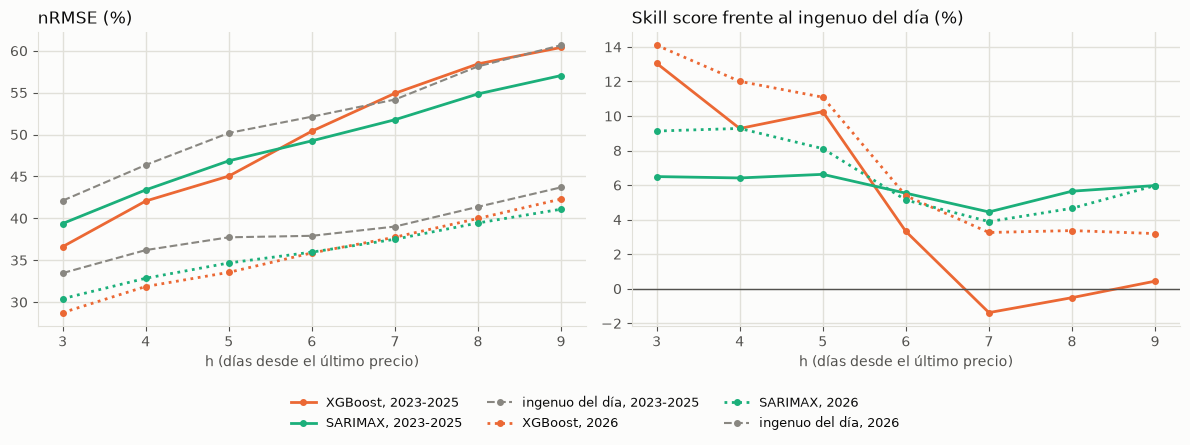

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, m, titulo in [(ejes[0], "nRMSE", "nRMSE (%)"), (ejes[1], "skill", "Skill score frente al ingenuo del día (%)")]:
    for p, ls in zip(PERIODOS, ["-", ":"]):
        for mo in MODELOS + ([REFERENCIA] if m == "nRMSE" else []):
            d = por_h.loc[(p, mo)]
            ax.plot(d.index, d[m], color=COLOR[mo], ls=ls if mo not in REFS else "--", marker="o", ms=4,
                    lw=1.5 if mo in REFS else 2, label=f"{mo}, {p}")
    if m == "skill":
        ax.axhline(0, color=TEXTO_2, lw=1)
    ax.set_title(titulo, loc="left")
    ax.set_xlabel("h (días desde el último precio)")
    ax.set_xticks(HS)
fig.tight_layout()
fig.legend(*ejes[0].get_legend_handles_labels(), frameon=False, fontsize=9, ncol=3,
           loc="upper center", bbox_to_anchor=(0.5, 0.0))
guardar_figura(fig, "nrmse_y_skill_por_horizonte.png")

## 5. MAPE por hora del día

Como las figuras 17, 20 y 23 del paper: una curva por horizonte, del más cercano (claro) al
más lejano (oscuro). 2023-2025.

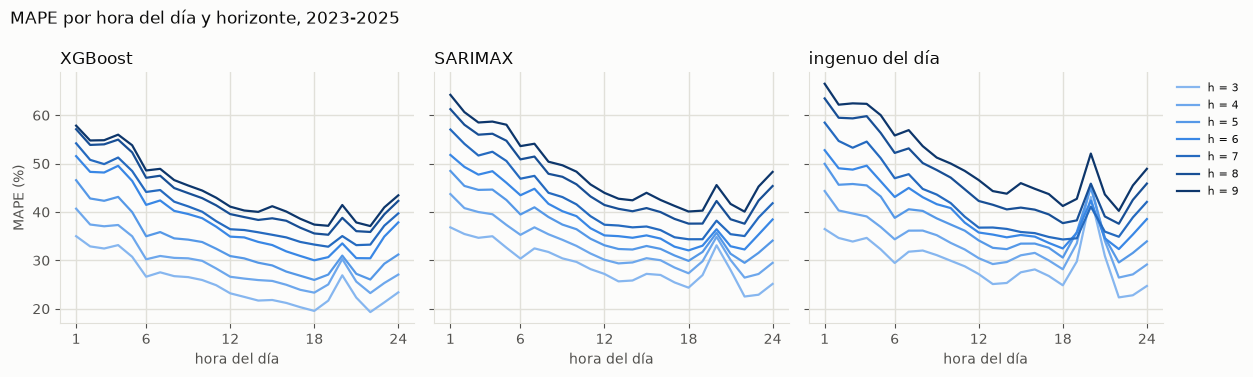

In [7]:
mape_hora = (largo[largo["periodo"] == "2023-2025"]
             .assign(ape=lambda d: 100 * d["error"].abs() / d["precio real"])
             .groupby(["modelo", "h", "hora"])["ape"].mean())
mape_hora.round(2).to_csv(SALIDA / "mape_por_hora_2023_2025.csv")

paneles = MODELOS + [REFERENCIA]
fig, ejes = plt.subplots(1, len(paneles), figsize=(4.2 * len(paneles), 3.8), sharey=True)
for ax, mo in zip(ejes, paneles):
    for h, c in zip(HS, AZULES):
        d = mape_hora.loc[(mo, h)]
        ax.plot(d.index, d.values, color=c, lw=1.6, label=f"h = {h}")
    ax.set_title(mo, loc="left")
    ax.set_xlabel("hora del día")
    ax.set_xticks([1, 6, 12, 18, 24])
ejes[0].set_ylabel("MAPE (%)")
ejes[-1].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("MAPE por hora del día y horizonte, 2023-2025", x=0.01, ha="left")
fig.tight_layout()
guardar_figura(fig, "mape_por_hora_2023_2025.png")

## 6. Mejor modelo por horizonte y hora

Como las figuras 10 a 12 del paper: el color de cada celda dice qué modelo tuvo el menor
error en ese horizonte y esa hora, y el número es ese error. Compiten los modelos y los dos
ingenuos. 2023-2025.

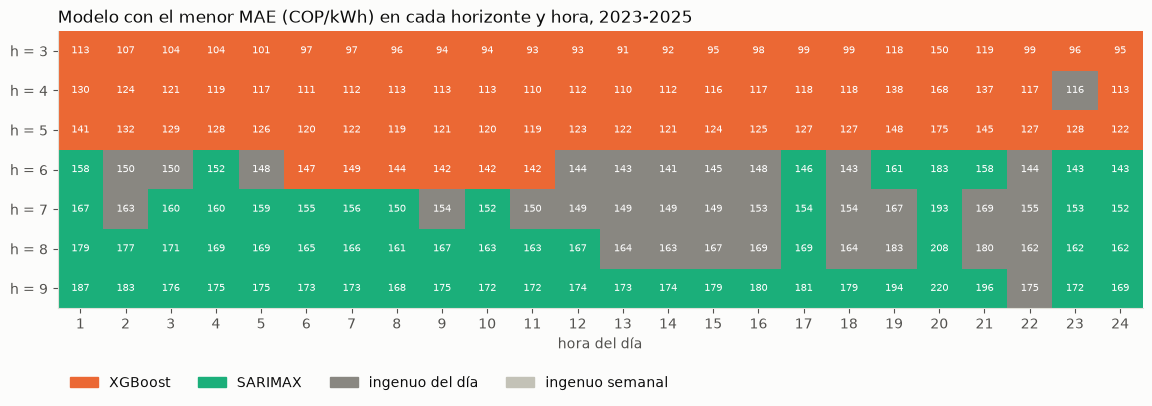

MAE: celdas ganadas de 168 -> {'XGBoost': 77, 'SARIMAX': 59, 'ingenuo del día': 32}


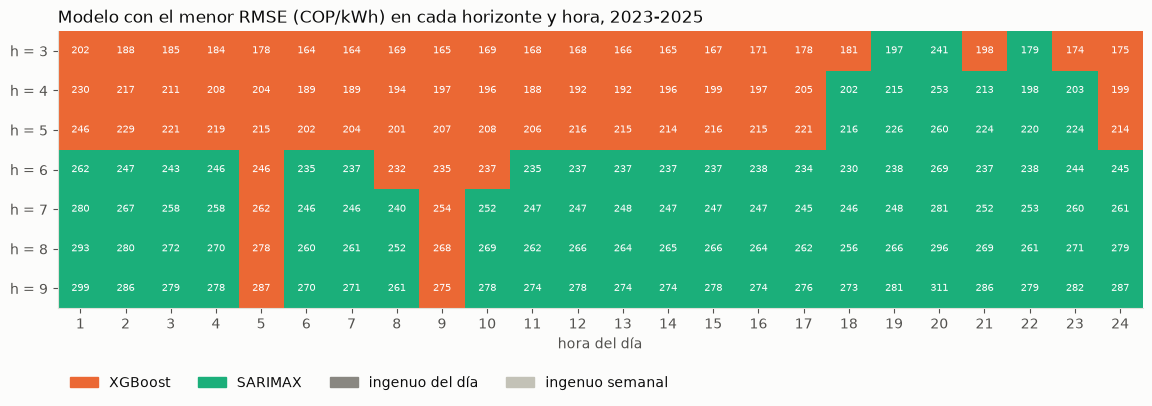

RMSE: celdas ganadas de 168 -> {'SARIMAX': 101, 'XGBoost': 67}


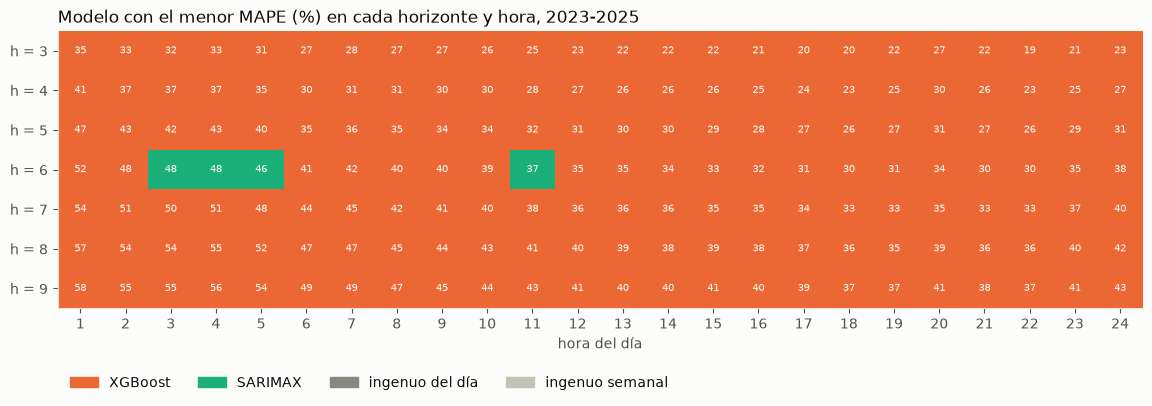

MAPE: celdas ganadas de 168 -> {'XGBoost': 164, 'SARIMAX': 4}


In [8]:
def mapa_mejor(metrica, nombre, unidad):
    d = largo[largo["periodo"] == "2023-2025"]
    if metrica == "MAPE":
        v = d.assign(x=100 * d["error"].abs() / d["precio real"]).groupby(["h", "hora", "modelo"])["x"].mean()
    elif metrica == "MAE":
        v = d.assign(x=d["error"].abs()).groupby(["h", "hora", "modelo"])["x"].mean()
    else:
        v = np.sqrt(d.assign(x=d["error"] ** 2).groupby(["h", "hora", "modelo"])["x"].mean())
    tabla = v.unstack("modelo")[TODOS]
    mejor = tabla.idxmin(axis=1)
    valor = tabla.min(axis=1)
    codigo = mejor.map({m: i for i, m in enumerate(TODOS)}).unstack("hora")
    fig, ax = plt.subplots(figsize=(14, 3.6))
    ax.imshow(codigo.to_numpy(), cmap=ListedColormap([COLOR[m] for m in TODOS]), vmin=-0.5,
              vmax=len(TODOS) - 0.5, aspect="auto")
    for i, h in enumerate(codigo.index):
        for j, hora in enumerate(codigo.columns):
            m = mejor.loc[(h, hora)]
            # texto blanco sobre los colores fuertes y oscuro sobre el amarillo y el gris claro
            ax.text(j, i, f"{valor.loc[(h, hora)]:.0f}", ha="center", va="center", fontsize=7,
                    color=TEXTO if m in ("LSTM", "ingenuo semanal") else "#ffffff")
    ax.set_yticks(range(len(codigo.index)), [f"h = {h}" for h in codigo.index])
    ax.set_xticks(range(24), range(1, 25))
    ax.set_xlabel("hora del día")
    ax.grid(False)
    a_mano = [plt.Rectangle((0, 0), 1, 1, color=COLOR[m]) for m in TODOS]
    ax.legend(a_mano, TODOS, frameon=False, ncol=len(TODOS), loc="upper left", bbox_to_anchor=(0, -0.2))
    ax.set_title(f"Modelo con el menor {metrica} ({unidad}) en cada horizonte y hora, 2023-2025", loc="left")
    guardar_figura(fig, nombre)
    return mejor.value_counts()


for metrica, unidad in [("MAE", "COP/kWh"), ("RMSE", "COP/kWh"), ("MAPE", "%")]:
    cuenta = mapa_mejor(metrica, f"mejor_modelo_{metrica.lower()}_2023_2025.png", unidad)
    print(f"{metrica}: celdas ganadas de 168 ->", cuenta.to_dict())

## 7. Semanas de ejemplo

El paper muestra días de poca nubosidad, de poca irradiancia y de mucha variabilidad. Aquí el
equivalente son tres semanas del test elegidas con una regla fija: entre los cortes de
2023-2025, la semana con el menor, el mediano y el mayor coeficiente de variación del precio
real en sus 168 horas. Se agrega la semana final del 9 al 15 de octubre de 2026, que se
pronosticó con el corte del 6 de octubre.

{'menos variable': 'corte 2024-09-15, CV 0.01', 'variación mediana': 'corte 2023-01-21, CV 0.27', 'más variable': 'corte 2025-08-05, CV 1.16'}


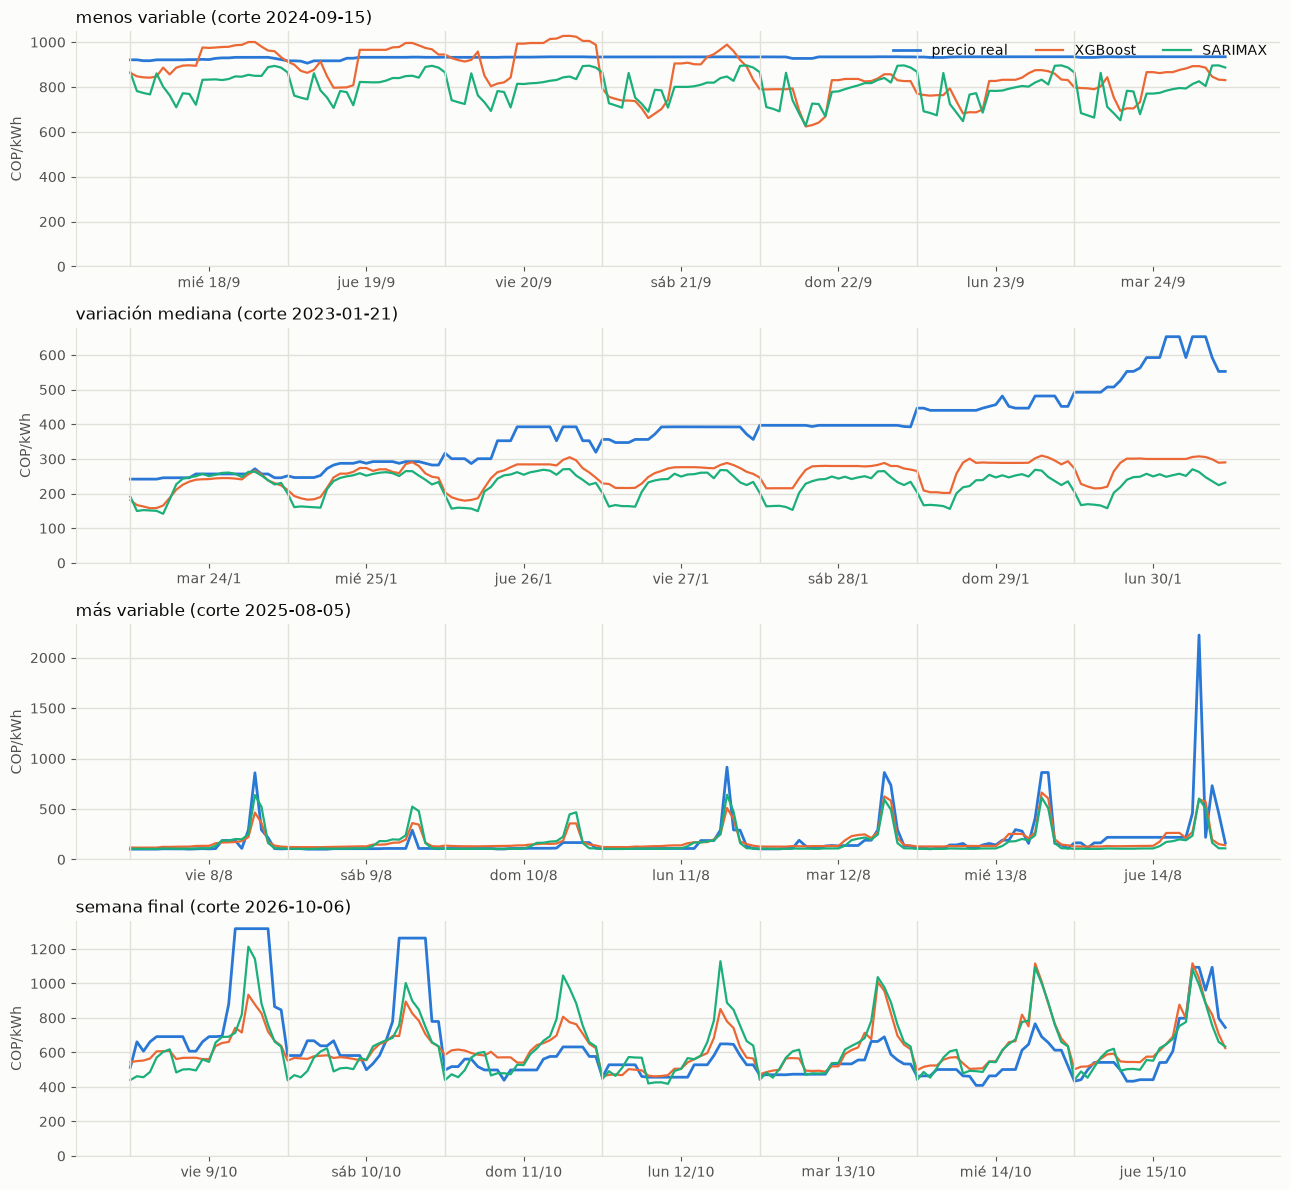

pearson            MAPE        
modelo                               SARIMAX XGBoost SARIMAX XGBoost
semana                                                              
menos variable (corte 2024-09-15)       0.11   -0.06   14.48   10.39
más variable (corte 2025-08-05)         0.70    0.75   24.79   27.65
semana final (corte 2026-10-06)         0.63    0.64   17.94   15.94
variación mediana (corte 2023-01-21)    0.18    0.59   37.17   29.96

In [9]:
semanas = ancho[ancho["periodo"] == "2023-2025"].groupby("fecha").filter(lambda g: len(g) == 168)
cv = semanas.groupby("fecha")["precio real"].agg(lambda s: s.std() / s.mean()).sort_values()
elegidas = {"menos variable": cv.index[0], "variación mediana": cv.index[len(cv) // 2],
            "más variable": cv.index[-1]}
print({k: f"corte {v.date()}, CV {cv[v]:.2f}" for k, v in elegidas.items()})


def semana_final():
    real = pd.read_csv("resultados/modelo_xgboost/precio_real_final.csv", parse_dates=["fecha_objetivo"])
    xg = pd.read_csv("resultados/modelo_xgboost/pronostico_final.csv", parse_dates=["fecha_objetivo"])
    sa = pd.read_csv("resultados/modelo_sarimax/pronostico_final.csv", parse_dates=["fecha"])
    sa["fecha_objetivo"] = sa["fecha"] + pd.to_timedelta(sa["h"], unit="D")
    d = (xg[["fecha_objetivo", "hora", "h", "precio_pron", "precio_t"]]
         .merge(real, on=["fecha_objetivo", "hora"])
         .merge(sa.assign(SARIMAX=np.exp(sa["lp_hat"]))[["fecha_objetivo", "hora", "SARIMAX"]],
                on=["fecha_objetivo", "hora"]))
    assert len(d) == 168
    return d.rename(columns={"precio_pron": "XGBoost", "precio_real": "precio real",
                             "precio_t": "ingenuo del día"}).sort_values(["fecha_objetivo", "hora"])


def una_semana(corte):
    d = ancho[ancho["fecha"] == corte].copy()
    d["fecha_objetivo"] = d["fecha"] + pd.to_timedelta(d["h"], unit="D")
    return d.sort_values(["fecha_objetivo", "hora"])


casos = {f"{k} (corte {v.date()})": una_semana(v) for k, v in elegidas.items()}
casos["semana final (corte 2026-10-06)"] = semana_final()

dias_es = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
fig, ejes = plt.subplots(len(casos), 1, figsize=(13, 3.0 * len(casos)))
correlaciones = []
for ax, (titulo, d) in zip(ejes, casos.items()):
    momento = d["fecha_objetivo"] + pd.to_timedelta(d["hora"] - 1, unit="h")
    ax.plot(momento, d["precio real"], color=COLOR["precio real"], label="precio real")
    for mo in [m for m in MODELOS if m in d]:
        ax.plot(momento, d[mo], color=COLOR[mo], lw=1.6, label=mo)
        correlaciones.append(dict(semana=titulo, modelo=mo, pearson=np.corrcoef(d["precio real"], d[mo])[0, 1],
                                  MAPE=100 * np.mean(np.abs(d[mo] - d["precio real"]) / d["precio real"])))
    dias = pd.date_range(d["fecha_objetivo"].min(), d["fecha_objetivo"].max())
    ax.set_xticks(dias + pd.Timedelta(hours=12),
                  [f"{dias_es[x.dayofweek]} {x.day}/{x.month}" for x in dias])
    for x in dias:
        ax.axvline(x, color=REJILLA, lw=1)
    ax.set_ylim(bottom=0)
    ax.set_ylabel("COP/kWh")
    ax.set_title(titulo, loc="left")
    ax.grid(axis="x", visible=False)
ejes[0].legend(frameon=False, ncol=4, loc="upper right")
fig.tight_layout()
guardar_figura(fig, "semanas_de_ejemplo.png")

correlaciones = pd.DataFrame(correlaciones)
correlaciones.round(3).to_csv(SALIDA / "semanas_de_ejemplo.csv", index=False)
display(correlaciones.pivot(index="semana", columns="modelo", values=["pearson", "MAPE"]).round(2))

## 8. Correlación con el precio real

Como las figuras 30, 31, 34 y 35 del paper, pero con todas las horas del test 2023-2025 y no
con un solo día. Cada punto es una hora pronosticada; el color muestra cuántas caen en cada
zona, en escala logarítmica. La línea es pronóstico igual a real. Para que se lea, el dibujo
llega hasta el percentil 99,5 del precio real; el coeficiente de Pearson usa todas las horas.

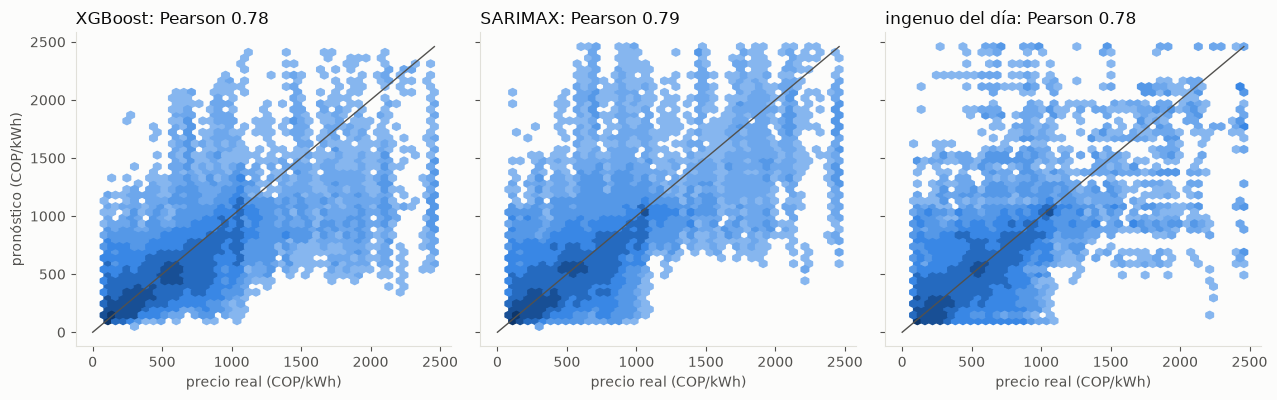

In [10]:
d = ancho[ancho["periodo"] == "2023-2025"]
paneles = MODELOS + [REFERENCIA]
fig, ejes = plt.subplots(1, len(paneles), figsize=(4.3 * len(paneles), 4.1), sharex=True, sharey=True)
tope = np.quantile(d["precio real"], 0.995)
for ax, mo in zip(ejes, paneles):
    dentro = (d["precio real"] <= tope) & (d[mo] <= tope)
    ax.hexbin(d.loc[dentro, "precio real"], d.loc[dentro, mo], gridsize=45, extent=(0, tope, 0, tope), mincnt=1,
              cmap=ListedColormap(AZULES), bins="log")
    ax.plot([0, tope], [0, tope], color=TEXTO_2, lw=1)
    r = np.corrcoef(d["precio real"], d[mo])[0, 1]
    ax.set_title(f"{mo}: Pearson {r:.2f}", loc="left")
    ax.set_xlabel("precio real (COP/kWh)")
    ax.grid(False)
ejes[0].set_ylabel("pronóstico (COP/kWh)")
fig.tight_layout()
guardar_figura(fig, "correlacion_2023_2025.png")

## 9. Hiperparámetros

Como las tablas 7 a 9 del paper.

In [11]:
cfg = json.load(open("resultados/modelo_xgboost/configuracion_final.json", encoding="utf-8"))
xgb_tabla = pd.DataFrame({f"h = {a}" + (" (y 8, 9)" if a == "7" else ""): v["parametros"]
                          for a, v in cfg.items() if a in [str(h) for h in range(3, 8)]}).T
xgb_tabla["learning_rate"] = 0.03
print("XGBoost: un modelo directo por horizonte; h = 8 y 9 usan la configuración de h = 7")
display(xgb_tabla)

sar = json.load(open("resultados/modelo_sarimax/configuracion_final.json", encoding="utf-8"))
o = sar["ordenes"][0]
print(f"\nSARIMAX: 24 modelos, uno por hora, con el mismo orden ({o['p']},{o['d']},{o['q']})"
      f"({o['P']},{o['D']},{o['Q']}) y s = 7; exógenas: {sar['exogenas'] or 'ninguna'}, más el festivo")
for nombre, carpeta in LSTMS.items():
    if (carpeta / "configuracion_final.json").exists():
        print(f"\n{nombre}:")
        display(pd.Series(json.load(open(carpeta / "configuracion_final.json", encoding="utf-8"))))
    else:
        print(f"\n{nombre}: todavía no existe")

XGBoost: un modelo directo por horizonte; h = 8 y 9 usan la configuración de h = 7


,max_depth,min_child_weight,n_estimators,subsample,colsample_bytree,reg_lambda,learning_rate
h = 3,4.0,50.0,200.0,0.75,0.82,8.39,0.03
h = 4,5.0,240.0,200.0,0.71,0.79,1.50,0.03
h = 5,3.0,50.0,300.0,0.72,0.75,8.46,0.03
h = 6,4.0,240.0,200.0,0.88,0.74,5.36,0.03
"h = 7 (y 8, 9)",6.0,50.0,100.0,0.74,0.54,3.80,0.03



SARIMAX: 24 modelos, uno por hora, con el mismo orden (1,1,2)(0,0,2) y s = 7; exógenas: ninguna, más el festivo

LSTM: todavía no existe


## 10. Cómo leer estos resultados

Semana completa (h = 3 a 9), en COP/kWh salvo los porcentajes:

| | XGBoost | SARIMAX | Ingenuo del día |
|---|---|---|---|
| MAE, 2023-2025 | 148,6 | 148,8 | 150,1 |
| RMSE, 2023-2025 | 247,5 | 242,1 | 257,1 |
| nRMSE, 2023-2025 | 50,4% | 49,3% | 52,3% |
| MBE, 2023-2025 | −46,4 | −15,3 | 1,3 |
| MAPE, 2023-2025 | 36,2% | 39,0% | 40,1% |
| Skill score, 2023-2025 | 3,7% | 5,8% | |
| RMSE, 2026 | 175,7 | 176,5 | 188,5 |
| MAPE, 2026 | 29,5% | 30,4% | 32,4% |
| Skill score, 2026 | 6,8% | 6,4% | |

- **En COP/kWh la comparación cambia.** Con el criterio de la tesis, el RMSE del logaritmo,
  XGBoost mejora 11,6% al ingenuo y SARIMAX 6,4% en 2023-2025. En COP/kWh el skill score de la
  semana es 3,7% y 5,8%. Por horizonte, XGBoost es mejor en h = 3 a 5 (13,1% en h = 3) y
  SARIMAX en h = 6 a 9; en h = 7 y 8 XGBoost queda por debajo del ingenuo (−1,4% y −0,5%). En
  2026 XGBoost es mejor hasta h = 6 y SARIMAX desde h = 7.
- **Por qué.** Los dos modelos pronostican el logaritmo del precio y se eligieron para
  minimizar ese error. Al volver a COP/kWh con exp(ŷ) se obtiene algo cercano a la mediana,
  no a la media: con un error en logaritmo de unos 0,44, la media queda cerca de 10% por
  encima de la mediana (exp(0,44²/2) ≈ 1,10). XGBoost pronostica en promedio 46 COP/kWh por
  debajo del real, unos 9% del precio medio. Además, en COP/kWh pesan mucho más los errores
  de los meses caros, que en logaritmo pesan igual que los de los baratos.
- **El MAPE favorece a XGBoost** (gana 164 de las 168 celdas) en parte por lo mismo: castiga
  más pronosticar por encima que por debajo.
- **Los intervalos de los modelos se cruzan** en casi todos los horizontes. Diferencias de
  unos pocos puntos no se pueden leer como ventajas claras; para eso está Diebold-Mariano.
- **Semanas de ejemplo.** En la menos variable (septiembre de 2024) el precio quedó casi plano
  en unos 934 COP/kWh; ningún modelo lo anticipa y la correlación ahí no dice nada. En la más
  variable (agosto de 2025) los dos siguen la forma de los picos pero no su tamaño. En la de
  variación mediana (enero de 2023) el precio subió toda la semana y los dos se quedaron
  abajo.

Diferencias de método con el paper:

| | Salazar-Peña et al. (2025) | Aquí |
|---|---|---|
| Qué se pronostica | Irradiancia solar | Precio de bolsa |
| Resolución y horizonte | 10 minutos, hasta 6 horas | Una hora, de 3 a 9 días |
| División de los datos | 80%, 10% y 10% | Se elige con 2015-2022 y se prueba en 2023-2025 y 2026, con walk-forward mensual |
| Pérdida | MAE | Error cuadrático del logaritmo |
| Referencia del skill score | Transformer | Ingenuo del día |
| Intervalos | t al 95% | t al 95% sobre el error de cada día |